# **SVC (Support Vector Classifier) - Diabetes Dataset**
Target: `diabetes` (0 = No, 1 = Yes)

**SVC:** finds the boundary that separates the two classes with the **widest margin**. Only the points closest to the boundary (the *support vectors*) decide where it goes. With the `rbf` kernel the boundary can be curved.

Main hyperparameters:
- `C` : penalty for wrong points. Big C = fit the training data tightly (can overfit), small C = smoother boundary
- `gamma` (rbf kernel): how far the influence of one point reaches. Big gamma = very wiggly boundary (overfit), small gamma = smooth
- `kernel` : `linear` (straight boundary) or `rbf` (curved boundary)
- `class_weight` : `'balanced'` gives more weight to the rare class

**Imbalance:** only ~9% of patients are diabetic. We use a stratified split, `class_weight='balanced'` and **threshold tuning** on the SVC decision score, and we judge with recall / F1 / ROC-AUC (not accuracy).

**Speed trick:** SVC gets slow on large data (training time grows roughly with n squared). So we **tune the parameters on a stratified sample of 15,000 rows**, then **train the final model on all training rows** with the best parameters.

Data: `diabetes_after_preprocessing.csv` (already scaled, 96,030 rows). SVC needs scaled features, so this is ready to use.

### 1. Import

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             precision_recall_curve, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

### 2. Load data, check imbalance, stratified split

In [2]:
df = pd.read_csv('../1. Data_Preprocessing/For_Classification/diabetes_after_preprocessing.csv')
x = df.drop('diabetes', axis=1)
y = df['diabetes']
print(df.shape, '| Diabetic %:', round(y.mean() * 100, 2))

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
print('Diabetic % train:', round(y_train.mean() * 100, 2), '| test:', round(y_test.mean() * 100, 2))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# stratified sample of 15,000 rows, used only for tuning
x_tune, _, y_tune, _ = train_test_split(x_train, y_train, train_size=15000, random_state=0, stratify=y_train)
print('Tuning sample:', x_tune.shape, '| Diabetic %:', round(y_tune.mean() * 100, 2))

(96030, 12) | Diabetic %: 8.83
Diabetic % train: 8.83 | test: 8.83
Tuning sample: (15000, 11) | Diabetic %: 8.83


### 3. Tune SVC (GridSearchCV on the 15,000-row sample)
Scored with **ROC-AUC** (uses the SVC decision score, does not depend on a threshold, not fooled by imbalance).

In [ ]:
%%time
param_grid = {
    'C': [0.03, 0.1, 0.3, 1, 10, 100],
    'gamma': [0.003, 0.01, 0.03, 0.1],
}

grid = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=cv, scoring='roc_auc', n_jobs=-1, return_train_score=True)
grid.fit(x_tune, y_tune)

print('Best Params :', grid.best_params_)
print('Best CV AUC :', round(grid.best_score_, 4))
print('Train AUC   :', round(grid.cv_results_['mean_train_score'][grid.best_index_], 4))

### 4. C and gamma vs ROC-AUC
Dashed = train AUC, solid = CV AUC. A big gap (train far above CV) means overfitting; this happens for big `C` and big `gamma`.

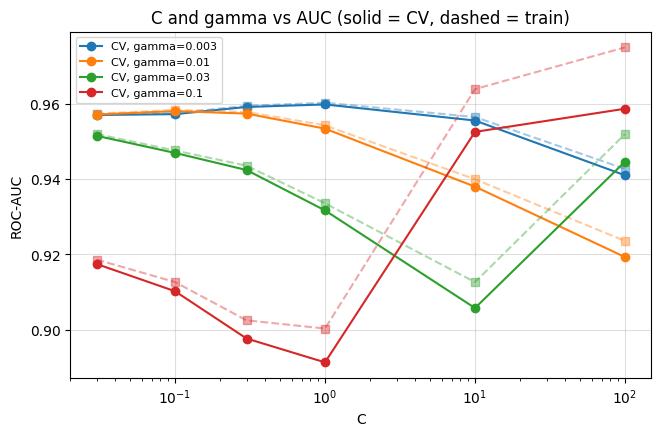

In [ ]:
res = pd.DataFrame(grid.cv_results_)
res['gamma'] = res['param_gamma'].astype(str)
res['C'] = res['param_C'].astype(float)

plt.figure(figsize=(7.5, 4.5))
for g, r in res.groupby('gamma'):
    r = r.sort_values('C')
    line, = plt.semilogx(r['C'], r['mean_test_score'], 'o-', label=f'CV, gamma={g}')
    plt.semilogx(r['C'], r['mean_train_score'], 's--', color=line.get_color(), alpha=0.4)
plt.xlabel('C'); plt.ylabel('ROC-AUC'); plt.title('C and gamma vs AUC (solid = CV, dashed = train)')
plt.legend(fontsize=8); plt.grid(alpha=0.4); plt.show()

### 5. Train the final SVC on ALL training rows (best parameters)
`class_weight` is added here for the imbalance strategies below.

In [ ]:
%%time
best_params = grid.best_params_

plain = SVC(kernel='rbf', **best_params).fit(x_train, y_train)
balanced = SVC(kernel='rbf', class_weight='balanced', **best_params).fit(x_train, y_train)

# decision score: > 0 means class 1 (diabetes). Bigger = more sure.
s_plain = plain.decision_function(x_test)
s_bal = balanced.decision_function(x_test)
print('Support vectors (plain):', plain.n_support_.sum(), 'of', len(x_train))

Support vectors (plain): 8475 of 76824
CPU times: user 1min 37s, sys: 226 ms, total: 1min 37s
Wall time: 1min 38s


### 6. Handle imbalance (3 strategies)
SVC gives a **decision score** (distance from the boundary). Default rule: score > 0 = diabetic.
1. **Plain**, threshold 0
2. **`class_weight='balanced'`**, threshold 0 (mistakes on the rare class cost more)
3. **Plain + tuned threshold:** choose the score cut-off with the best F1 (found from CV predictions on the training data only)

In [ ]:
%%time
# out-of-fold decision scores of the plain model (training data only)
oof = cross_val_predict(clone(plain), x_train, y_train, cv=cv, method='decision_function', n_jobs=-1)
prec, rec, thr = precision_recall_curve(y_train, oof)
f1_curve = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = thr[np.argmax(f1_curve)]
print('Best score threshold (max CV F1):', round(best_thr, 3))

def scores(name, score, threshold):
    pred = (score >= threshold).astype(int)
    return {'Strategy': name, 'Threshold': round(threshold, 3), 'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred), 'ROC_AUC': roc_auc_score(y_test, score)}

pd.DataFrame([scores('1. Plain (threshold 0)', s_plain, 0),
              scores('2. class_weight=balanced (0)', s_bal, 0),
              scores('3. Plain + tuned threshold', s_plain, best_thr)]).set_index('Strategy').round(4)

Best score threshold (max CV F1): -0.464
CPU times: user 1min 14s, sys: 142 ms, total: 1min 14s
Wall time: 1min 15s


,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
Strategy,,,,,,
1. Plain (threshold 0),0.000,0.9599,0.9658,0.5660,0.7138,0.9550
2. class_weight=balanced (0),0.000,0.8849,0.4264,0.8803,0.5746,0.9592
3. Plain + tuned threshold,-0.464,0.9583,0.8362,0.6562,0.7354,0.9550


### 7. Threshold table (precision vs recall trade-off)
Lower threshold = find more diabetic patients (higher recall) but more false alarms.

In [ ]:
rows = []
for t in [0.5, 0.0, -0.2, -0.4, -0.6]:
    pred = (s_plain >= t).astype(int)
    rows.append({'Threshold': t, 'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred), 'Missed diabetic': int(((pred == 0) & (y_test == 1)).sum()),
                 'False alarms': int(((pred == 1) & (y_test == 0)).sum())})
pd.DataFrame(rows).set_index('Threshold').round(3)

,Precision,Recall,F1,Missed diabetic,False alarms
Threshold,,,,,
0.5,0.999,0.476,0.645,889,1
0.0,0.966,0.566,0.714,736,34
-0.2,0.924,0.600,0.727,679,84
-0.4,0.865,0.644,0.739,603,170
-0.6,0.776,0.691,0.731,524,338


### 8. Final model: plain SVC + tuned threshold
Change `final_threshold` if you prefer more recall.

              precision    recall  f1-score   support

 No diabetes       0.97      0.99      0.98     17510
    Diabetes       0.84      0.66      0.74      1696

    accuracy                           0.96     19206
   macro avg       0.90      0.82      0.86     19206
weighted avg       0.96      0.96      0.96     19206



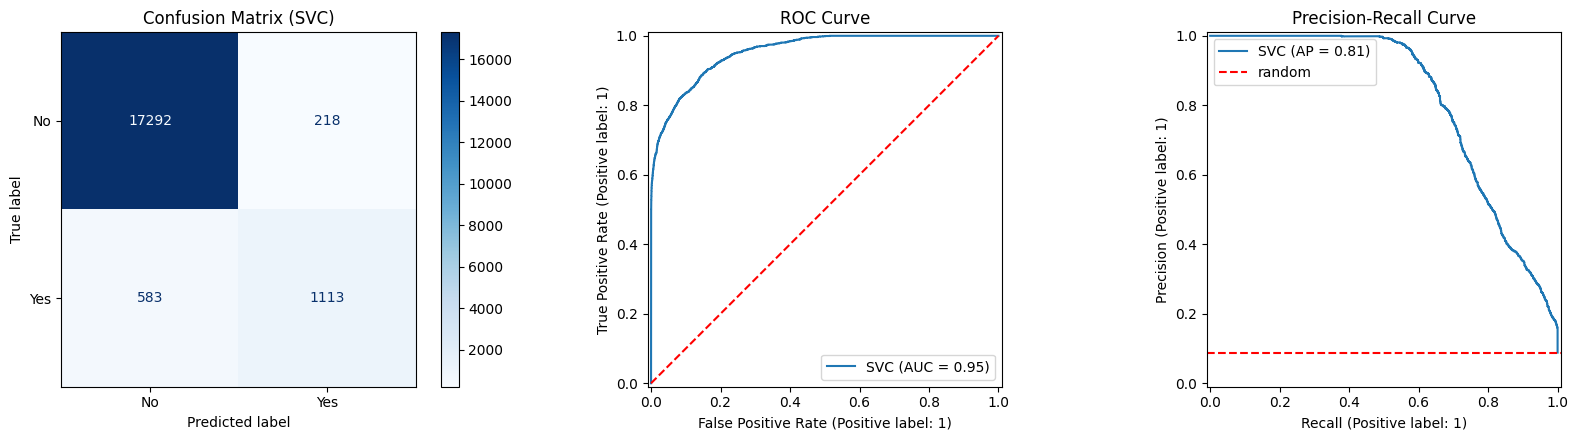

In [ ]:
final_threshold = best_thr
final_pred = (s_plain >= final_threshold).astype(int)

print(classification_report(y_test, final_pred, target_names=['No diabetes', 'Diabetes']))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, final_pred, display_labels=['No', 'Yes'], cmap='Blues', ax=ax[0])
ax[0].set_title('Confusion Matrix (SVC)')
RocCurveDisplay.from_predictions(y_test, s_plain, name='SVC', ax=ax[1]); ax[1].plot([0, 1], [0, 1], 'r--')
ax[1].set_title('ROC Curve')
PrecisionRecallDisplay.from_predictions(y_test, s_plain, name='SVC', ax=ax[2])
ax[2].axhline(y_test.mean(), color='r', ls='--', label='random'); ax[2].legend(); ax[2].set_title('Precision-Recall Curve')
plt.tight_layout(); plt.show()

### 9. Linear vs RBF kernel, and comparison with other models
- **LinearSVC** (straight boundary, very fast) shows if the curved boundary of `rbf` is really needed.
- Logistic Regression and binned Naive Bayes are added as references (best parameters from the earlier notebooks, same split).

In [ ]:
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

cont_cols = ['age', 'bmi', 'hba1c_level', 'blood_glucose_level']
bin_cols = [c for c in x.columns if c not in cont_cols]

lin_svc = LinearSVC(C=1, max_iter=5000).fit(x_train, y_train)
logit = LogisticRegression(solver='liblinear', C=0.316, penalty='l2').fit(x_train, y_train)
nbayes = Pipeline([('prep', ColumnTransformer([('cont', KBinsDiscretizer(n_bins=20, encode='ordinal', strategy='uniform'), cont_cols),
                                               ('bin', 'passthrough', bin_cols)])),
                   ('model', CategoricalNB(alpha=0.01, min_categories=20))]).fit(x_train, y_train)

compare = pd.DataFrame([
    scores('SVC rbf (+ tuned threshold)', s_plain, final_threshold),
    scores('LinearSVC (threshold 0)', lin_svc.decision_function(x_test), 0),
    scores('Logistic Regression (0.5)', logit.predict_proba(x_test)[:, 1], 0.5),
    scores('Naive Bayes - binned (0.5)', nbayes.predict_proba(x_test)[:, 1], 0.5),
]).set_index('Strategy')
compare.round(4)

,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
Strategy,,,,,,
SVC rbf (+ tuned threshold),-0.464,0.9583,0.8362,0.6562,0.7354,0.9550
LinearSVC (threshold 0),0.000,0.9587,0.8956,0.6020,0.7200,0.9589
Logistic Regression (0.5),0.500,0.9581,0.8626,0.6256,0.7252,0.9593
Naive Bayes - binned (0.5),0.500,0.9607,0.8147,0.7182,0.7634,0.9708


### 10. Save the model (.pkl)
The final SVC is trained on all data (best parameters). The threshold is saved with it.

In [ ]:
%%time
final_svc = SVC(kernel='rbf', **best_params).fit(x, y)

package = {'model': final_svc, 'threshold': float(final_threshold), 'features': list(x.columns), 'params': best_params}
joblib.dump(package, 'svc_diabetes_model.pkl', compress=3)
res.drop(columns=['params', 'gamma']).to_csv('svc_tuning_results.csv', index=False)

#Load and predict
pkg = joblib.load('svc_diabetes_model.pkl')
score = pkg['model'].decision_function(x_test.iloc[:5][pkg['features']])
print('Decision score:', score.round(3))
print('Prediction    :', (score >= pkg['threshold']).astype(int))
print('Actual        :', y_test.iloc[:5].values)

Decision score: [-1.791 -1.354 -2.664 -0.755 -3.757]
Prediction    : [0 0 0 0 0]
Actual        : [0 0 0 1 0]
CPU times: user 29.3 s, sys: 41.9 ms, total: 29.3 s
Wall time: 29.7 s


(These 5 rows were also in the training data of the final model. This cell only checks that the saved file loads and predicts. The honest accuracy is in the test tables above.)

### 11. Download (Google Colab only)

In [ ]:
try:
    from google.colab import files
    files.download('svc_diabetes_model.pkl')
    files.download('svc_tuning_results.csv')
except ImportError:
    print('Not Colab - files are saved in the notebook folder.')

Not Colab - files are saved in the notebook folder.
